In [6]:
import numpy as np
from common.layer import Affine, Relu, SoftmaxWithLoss
from common.gradient import numerical_gradient
from collections import OrderedDict

class TwoLayerNet:
    def __init__(
        self,
        input_size,          # 入力層のニューロン（ノード）数
        hidden_size,         # 隠れ層のニューロン数
        output_size,         # 出力層のニューロン数
        weight_init_std=0.01 # 標準偏差（本来なら、ReLUなのでHeの初期値を使用すべきではある）
    ):
        self.params = {}
        self.params['W1'] = weight_init_std * np.random.randn(input_size, hidden_size)  # 正規分布から乱数で重みの初期値を決める
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

        self.layers = OrderedDict()  # 代入された順番を記憶している Dictionary （forで順番に処理できる）
        self.layers['Affine1'] = Affine(self.params['W1'], self.params['b1'])
        self.layers['Relu1'] = Relu()
        self.layers['Affine2'] = Affine(self.params['W2'], self.params['b2'])
        self.lastLayer = SoftmaxWithLoss()

    def predict(self, x):
        for layer in self.layers.values():
            x = layer.forward(x)
        return x

    def loss(self, x, t):
        y = self.predict(x)
        return self.lastLayer.forward(y, t)

    def accuracy(self, x, t):
        y = self.predict(x)
        y = np.argmax(y, axis=1)
        if t.ndim != 1 : t = np.argmax(t, axis=1)

        accuracy = np.sum(y == t) / float(x.shape[0])
        return accuracy

    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)

        grads = {}
        grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
        grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
        grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
        grads['b2'] = numerical_gradient(loss_W, self.params['b2'])
        return grads

    def gradient(self, x, t):
        # forward
        self.loss(x, t)

        # backward
        dout = 1                             # ∂L/∂L = 1（損失を損失で微分すると 1）
        dout = self.lastLayer.backward(dout) # (y - t) / batch_size （softmax-with-loss）
        
        layers = list(self.layers.values())
        layers.reverse()
        for layer in layers:
            dout = layer.backward(dout)

        # setting
        grads = {}
        grads['W1'] = self.layers['Affine1'].dW
        grads['b1'] = self.layers['Affine1'].db
        grads['W2'] = self.layers['Affine2'].dW
        grads['b2'] = self.layers['Affine2'].db
        return grads

In [13]:
# 勾配確認
# 数値微分と誤差逆伝播法での勾配を比較することで、誤差逆伝播法の正しさを確認する
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

x_batch = x_train[:3]
t_batch = t_train[:3]

grad_numerical = network.numerical_gradient(x_batch, t_batch)
grad_backprop = network.gradient(x_batch, t_batch)

for key in grad_numerical.keys():
    diff = np.average(np.abs(grad_backprop[key] - grad_numerical[key]))
    print(key + ":" + str(diff))

W1:4.5138569767985046e-10
b1:2.3678661356804022e-09
W2:5.947304979766101e-09
b2:1.4035800951217591e-07


In [15]:
iters_num = 10000
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.1

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)

for i in range(iters_num):
    batch_mask = np.random.choice(train_size, batch_size) # 100 個の番号をランダムに選ぶ
    x_batch = x_train[batch_mask]                         # 上記で選んだ番号のデータを取り出す
    t_batch = t_train[batch_mask]                         # 上記で選んだ番号のデータを取り出す

    # 誤差逆伝播法によって、勾配を求める
    grad = network.gradient(x_batch, t_batch)

    # パラメータの更新
    for key in ('W1', 'b1', 'W2', 'b2'):
        network.params[key] -= learning_rate * grad[key]

    loss = network.loss(x_batch, t_batch)
    train_loss_list.append(loss)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)
        print("train: " + str(round(train_acc, 3)) + ", test: " + str(round(test_acc, 3)))

train: 0.13, test: 0.13
train: 0.904, test: 0.91
train: 0.925, test: 0.929
train: 0.935, test: 0.933
train: 0.945, test: 0.945
train: 0.952, test: 0.952
train: 0.957, test: 0.954
train: 0.961, test: 0.958
train: 0.965, test: 0.96
train: 0.965, test: 0.961
train: 0.97, test: 0.965
train: 0.973, test: 0.966
train: 0.975, test: 0.968
train: 0.975, test: 0.969
train: 0.975, test: 0.968
train: 0.978, test: 0.969
train: 0.98, test: 0.971


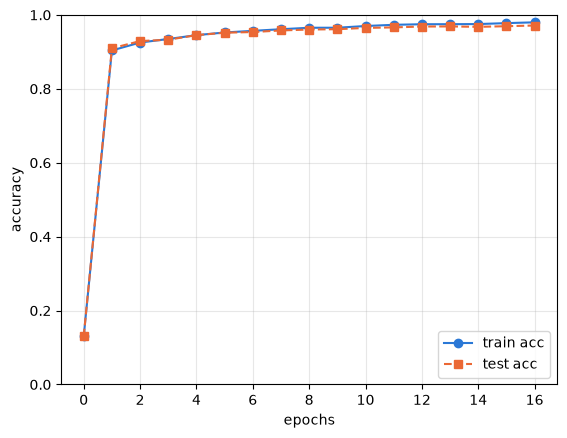

In [16]:
import matplotlib.pyplot as plt

epochs = np.arange(len(train_acc_list)) # 横軸: エポック数（0, 1, 2, ...）

plt.plot(epochs, train_acc_list, marker='o', color='#2a78d6', label='train acc')
plt.plot(epochs, test_acc_list, marker='s', color='#eb6834', linestyle='--', label='test acc')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.grid(alpha=0.3)       # 目盛り線を薄く表示
plt.legend(loc='lower right')
plt.show()